# Corporate PD across one to five year horizons (C02)

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- read the five horizon files of C02 and say why their event rates cannot be read as one cumulative PD curve;
- compare the models of the ladder on each horizon with the AUC, its DeLong interval and the overfit gap, and recompute the gap and the DeLong p-values from the committed numbers;
- recompute a Hosmer-Lemeshow p-value and a Jeffreys level test from the committed tables;
- read the cross-file transfer matrix and the pooled model with the firm-overlap caveat that limits both.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C02 is the PD of corporate borrowers at horizons of one to five years. The data is the UCI "Polish companies bankruptcy data" (Tomczak, 2016; CC BY 4.0, licence class `mirror-allowed`; https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data; DOI 10.24432/C5F600): five files of financial ratios of manufacturing companies (64 ratios per company) with a bankruptcy label, each for a forecast horizon. The pipeline fitted the ladder of seven models on each file with a locked, stratified holdout and on the five files stacked. Committed:

- `data/derived/C02/h1.json` to `h5.json`: one file per horizon, with the models' discrimination, calibration, overfit check and stability, the comparison of each challenger with the scorecard, the cross-file transfer and the battery of tests.
- `data/derived/C02/pooled.json`: the five files stacked with a horizon indicator.
- `data/derived/C02/models-polish-horizons.json`: the files and the split protocol.

The raw zip stays outside the repository (`data/derived/C02/raw-sources.txt` records its source row and checksum). The next cell loads the files and prints the event of each horizon as the file defines it.

In [2]:
# Load the five horizon files, the pooled file and the models file of C02
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C02"
horizons = ["h1", "h2", "h3", "h4", "h5"]
docs = {h: json.loads((derived / f"{h}.json").read_text(encoding="utf-8")) for h in horizons}
pooled = json.loads((derived / "pooled.json").read_text(encoding="utf-8"))
protocol = json.loads((derived / "models-polish-horizons.json").read_text(encoding="utf-8"))["fit"]

LANG = "en"
# The engine's light values, named in this language
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
for h in horizons:
    print(h, docs[h]["outputs"]["counts"]["event_definition"][LANG])
print("baked by riskvalidation", {d["provenance"]["riskvalidation_version"] for d in docs.values()}, "| installed", rv.__version__)


h1 Bankruptcy of the company within 1 year of the financial statements (the class label of the file 5year.arff)
h2 Bankruptcy of the company within 2 years of the financial statements (the class label of the file 4year.arff)
h3 Bankruptcy of the company within 3 years of the financial statements (the class label of the file 3year.arff)
h4 Bankruptcy of the company within 4 years of the financial statements (the class label of the file 2year.arff)
h5 Bankruptcy of the company within 5 years of the financial statements (the class label of the file 1year.arff)
baked by riskvalidation {'0.8.1'} | installed 0.8.1


## Method

### Step 1: five samples, not one cohort

Each file is a sample of companies with the ratios of one year and the bankruptcy status over a horizon. A tempting reading is to take the five event rates as the cumulative probability of bankruptcy at one, two, three, four and five years, and to read a term structure from them (the input of a lifetime expected credit loss). That reading needs one cohort of companies followed over five years, so that the share bankrupt can only grow with the horizon. The files are **independent samples of different forecast years**, not one cohort followed through time, and the UCI page gives no company identifier nor a date. The product's decision (G22) is to read no term structure from them. The first check the data allows is the one the cumulative reading would have to pass: strict growth with the horizon. The next cell prints the files, recomputes each event rate from its counts, checks the growth, and prints the split of each file (the holdout is stratified, so the holdout rate follows the file's).

In [3]:
# Print the five files with their event rates and splits, and test the growth with the horizon
print(f"{'horizon':9s} {'years':>5s} {'rows':>7s} {'bankrupt':>10s} {'rate':>7s} {'train':>7s} {'calibration':>9s} {'holdout':>10s} {'in holdout':>12s}")
rates = []
for h in horizons:
    o = docs[h]["outputs"]
    c, s = o["counts"], o["split"]
    rate = c["events"] / c["rows"]
    assert abs(rate - c["event_rate"]) < 1e-9
    rates.append(rate)
    print(f"{h:9s} {o['years']:5d} {c['rows']:7d} {c['events']:10d} {rate:7.4f} {s['train_rows']:7d} {s['calibration_rows']:9d} {s['holdout_rows']:10d} {s['holdout_events']:12d}")
print("strictly increasing with the horizon:", bool((np.diff(rates) > 0).all()))
print(docs["h3"]["outputs"]["term_structure_reason"][LANG])
print("expected credit loss effect committed in the file:", docs["h3"]["outputs"]["impact_detail"]["ecl_lifetime_effect"])


horizon   years    rows   bankrupt    rate   train calibration    holdout   in holdout
h1            1    5910        410  0.0694    3309       828       1773          123
h2            2    9792        515  0.0526    5483      1371       2938          155
h3            3   10503        495  0.0471    5881      1471       3151          149
h4            4   10173        400  0.0393    5696      1425       3052          120
h5            5    7027        271  0.0386    3934       984       2109           81
strictly increasing with the horizon: False
The five files are independent samples of different forecast years, not one cohort followed through time, so no cumulative PD is read from them. Their event rates (1y 0.0694, 2y 0.0526, 3y 0.0471, 4y 0.0393, 5y 0.0386) are not strictly increasing with the horizon, which a cumulative PD would be (decision G22).
expected credit loss effect committed in the file: None


### Step 2: the ladder on each horizon

The seven models are the same ladder as in notebooks 03 and 06: a one-variable baseline (P0), the WoE scorecard (P1), a penalised logistic regression (P2a), penalised trees (P2b), an explainable boosting machine (P3) and two boosted-tree models (P4). The AUC with its DeLong 95% interval (DeLong, DeLong and Clarke-Pearson, 1988) is committed for the holdout of each file, and the Gini coefficient is $2\,\mathrm{AUC} - 1$. The next cell checks that identity on every committed pair and prints the AUC by model and horizon, with the scorecard's interval; the figure draws the lines. A holdout of 81 to 155 bankruptcies per file gives wide intervals, which is the main limit of this case.

In [4]:
# Print the AUC of each model on each horizon and check the Gini identity
def rung_of(entry):
    return entry["model_id"].split("-", 1)[1]


rungs = [rung_of(x) for x in docs["h1"]["outputs"]["rungs"]]
auc = {h: {rung_of(x): x["discrimination"] for x in docs[h]["outputs"]["rungs"]} for h in horizons}
gini_gap = max(abs(d["gini"] - (2 * d["auc"] - 1)) for h in horizons for d in auc[h].values())
print("largest gap of the Gini identity:", f"{gini_gap:.1e}")
print(f"{'model':14s}" + "".join(f"{h:>8s}" for h in horizons))
for r in rungs:
    print(f"{r:14s}" + "".join(f"{auc[h][r]['auc']:8.3f}" for h in horizons))
print()
print(f"{'P1-scorecard':14s} 95% interval: " + " | ".join(f"{h} {auc[h]['P1-scorecard']['auc_ci']['lo']:.2f}-{auc[h]['P1-scorecard']['auc_ci']['hi']:.2f}" for h in horizons))


largest gap of the Gini identity: 0.0e+00
model               h1      h2      h3      h4      h5
P0-single        0.813   0.670   0.612   0.674   0.743
P1-scorecard     0.911   0.810   0.839   0.792   0.728
P2a-l1           0.912   0.835   0.867   0.812   0.758
P2b-pltr         0.934   0.904   0.890   0.897   0.903
P3-ebm           0.954   0.922   0.898   0.901   0.932
P4-lightgbm      0.952   0.923   0.925   0.912   0.943
P4-xgboost       0.941   0.912   0.901   0.889   0.927

P1-scorecard   95% interval: h1 0.89-0.93 | h2 0.77-0.85 | h3 0.80-0.88 | h4 0.75-0.84 | h5 0.67-0.78


The figure draws the AUC of each model against the horizon.

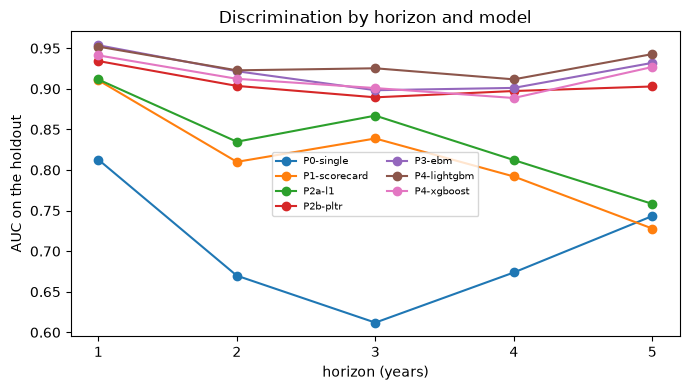

In [5]:
# Draw the AUC of each model against the horizon
fig, ax = plt.subplots(figsize=(7, 4))
for r in rungs:
    ax.plot([docs[h]["outputs"]["years"] for h in horizons], [auc[h][r]["auc"] for h in horizons], marker="o", label=r)
ax.set_xlabel("horizon (years)")
ax.set_ylabel("AUC on the holdout")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_title("Discrimination by horizon and model")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()


### Step 3: the overfit gap

A model that ranks well on the data it was fitted on and worse on new data has memorised noise. The committed check compares the AUC on the training slice with the AUC on the holdout; the gap is flagged when it exceeds a tolerance of 0.05 AUC points, a convention of the product (the research gives no value; the tolerance is about one and a half to three standard errors of an AUC at these holdout sizes). The next cell recomputes the gap and the flag for each model and horizon from the committed train and holdout AUC, and marks the flagged ones.

In [6]:
# Recompute the overfit gap and flag of each model and horizon from the committed train and holdout AUC
tolerance = docs["h1"]["outputs"]["parameters"][0]["value"]
print("tolerance:", tolerance, "| '*' marks a gap above the tolerance")
print(f"{'model':14s}" + "".join(f"{h:>9s}" for h in horizons))
flags_agree = []
for x in docs["h1"]["outputs"]["rungs"]:
    r = rung_of(x)
    line = f"{r:14s}"
    for h in horizons:
        o = next(e for e in docs[h]["outputs"]["rungs"] if rung_of(e) == r)["overfit"]
        gap = o["train_auc"] - o["holdout_auc"]
        flagged = gap > tolerance
        flags_agree.append(flagged == o["flag"])
        line += f"{gap:8.3f}{'*' if flagged else ' '}"
    print(line)
print("flags equal the committed flags:", all(flags_agree))


tolerance: 0.05 | '*' marks a gap above the tolerance
model                h1       h2       h3       h4       h5
P0-single       -0.027    0.049    0.050   -0.016   -0.005 
P1-scorecard     0.005    0.033    0.018    0.065*   0.092*
P2a-l1           0.023    0.029    0.015    0.067*   0.077*
P2b-pltr         0.039    0.071*   0.092*   0.085*   0.079*
P3-ebm           0.039    0.053*   0.081*   0.075*   0.062*
P4-lightgbm      0.048    0.077*   0.074*   0.088*   0.057*
P4-xgboost       0.055*   0.073*   0.095*   0.102*   0.063*
flags equal the committed flags: True


### Step 4: the challengers against the scorecard

For each horizon the file compares every challenger with the scorecard (the champion): the AUC difference with its DeLong interval, the p-value, the change of the Brier score, and the share of companies whose grade changes between the two. The DeLong interval is $\Delta \pm z_{0.975}\,\mathrm{SE}$, so the standard error is recovered from the interval and the p-value follows from the same normal law as in notebook 03:

$$\mathrm{SE} = \frac{\mathrm{hi} - \mathrm{lo}}{2 z_{0.975}}, \qquad z = \frac{\Delta}{\mathrm{SE}}, \qquad p = 2\,(1 - \Phi(|z|))$$

The next cell does that for the 25 comparisons (five horizons by five challengers) and prints the difference, the recomputed p-value, the committed one, and the share of companies that change grade.

In [7]:
# Recover the standard error from each DeLong interval and recompute the p-value of every challenger comparison
z975 = stats.norm.ppf(0.975)
print(f"{'horizon':8s} {'challenger':12s} {'AUC diff.':>10s} {'p recomputed':>16s} {'p committed':>14s} {'grade changes':>18s}")
gap_max = 0.0
for h in horizons:
    for c in docs[h]["outputs"]["challenger"]:
        ci = c["auc_diff_ci"]
        se = (ci["hi"] - ci["lo"]) / (2 * z975)
        z = c["auc_diff"] / se
        p = 2 * stats.norm.sf(abs(z))
        gap_max = max(gap_max, abs(np.log10(p) - np.log10(c["delong_p_value"])))
        print(f"{h:8s} {c['challenger'].split('-', 1)[1]:12s} {c['auc_diff']:10.4f} {p:16.3g} {c['delong_p_value']:14.3g} {c['grade_disagreement_share']:18.3f}")
print("largest gap between the two p-values, in orders of magnitude:", round(gap_max, 4))


horizon  challenger    AUC diff.     p recomputed    p committed      grade changes
h1       P2a-l1           0.0009            0.897          0.897              0.186
h1       P2b-pltr         0.0237          0.00256        0.00256              0.356
h1       P3-ebm           0.0431         7.45e-05       7.45e-05              0.394
h1       P4-lightgbm      0.0414         1.79e-06       1.79e-06              0.397
h1       P4-xgboost       0.0306          0.00113        0.00113              0.404
h2       P2a-l1           0.0248         0.000152       0.000152              0.129
h2       P2b-pltr         0.0936         6.46e-11       6.46e-11              0.500
h2       P3-ebm           0.1117         1.24e-14       1.24e-14              0.500
h2       P4-lightgbm      0.1128         6.26e-16       6.26e-16              0.495
h2       P4-xgboost       0.1023         3.79e-14       3.79e-14              0.497
h3       P2a-l1           0.0282          0.00157        0.00157            

### Step 5: calibration

Two committed numbers per model and horizon speak to calibration: the Hosmer-Lemeshow statistic with its degrees of freedom and p-value (notebook 03), and the level test on the whole holdout. The next cell recomputes the p-value of Hosmer-Lemeshow from its statistic and degrees of freedom with the chi-square law, prints the lights the policy gives to the HL p-values of each model and horizon, and calls the engine's Jeffreys test on the scorecard of each horizon, from the holdout size, its bankruptcies and the mean PD of its reliability bins, to compare with the committed level row.

In [8]:
# Recompute the Hosmer-Lemeshow p-values, show their lights and call the Jeffreys test on the scorecard of each horizon
from riskvalidation.validation import pd_jeffreys

policy = rv.default_policy()


def committed_row(h, test_id, rung):
    return next(t for t in docs[h]["tests"] if t["test_id"] == test_id and t["model_id"] == f"{h}-{rung}" and t["segment"] == "portfolio")


gap_max = 0.0
print(f"{'model':14s}" + "".join(f"{h:>13s}" for h in horizons))
for r in rungs:
    line = f"{r:14s}"
    for h in horizons:
        hl = next(e for e in docs[h]["outputs"]["rungs"] if rung_of(e) == r)["calibration"]["hosmer_lemeshow"]
        p = stats.chi2.sf(hl["statistic"], hl["df"])
        gap_max = max(gap_max, abs(p - hl["p_value"]))
        line += f"{p:9.4f} {LIGHT[committed_row(h, 'pd.hosmer_lemeshow', r)['light']][:3]:>3s}"
    print(line)
print("largest gap with the committed HL p-value:", f"{gap_max:.1e}")
print()
for h in horizons:
    o = docs[h]["outputs"]
    x = next(e for e in o["rungs"] if rung_of(e) == "P1-scorecard")
    mean_pd = sum(b["n"] * b["pd"] for b in x["reliability"]) / sum(b["n"] for b in x["reliability"])
    jef = pd_jeffreys(n=o["split"]["holdout_rows"], d=o["split"]["holdout_events"], pd=mean_pd, policy=policy, model_id=f"{h}-P1-scorecard", segment="portfolio")
    row = committed_row(h, "pd.jeffreys", "P1-scorecard")
    print(f"{h} P1: N {jef.n} D {jef.n_events} mean PD {mean_pd:.4f} | p Jeffreys {jef.p_value:.4f} | committed {row['p_value']:.4f} | {LIGHT[row['light']]}")


model                    h1           h2           h3           h4           h5
P0-single        0.0000 red   0.0000 red   0.0000 red   0.0000 red   0.0000 red
P1-scorecard     0.3511 gre   0.8203 gre   0.0705 gre   0.0258 amb   0.0005 red
P2a-l1           0.0267 amb   0.5706 gre   0.1510 gre   0.0003 red   0.0552 gre
P2b-pltr         0.5956 gre   0.0000 red   0.0108 amb   0.0065 red   0.0000 red
P3-ebm           0.7663 gre   0.0380 amb   0.0000 red   0.1212 gre   0.2226 gre
P4-lightgbm      0.0787 gre   0.0000 red   0.1065 gre   0.0008 red   0.6778 gre
P4-xgboost       0.0028 red   0.0000 red   0.0000 red   0.0013 red   0.5702 gre
largest gap with the committed HL p-value: 0.0e+00

h1 P1: N 1773 D 123 mean PD 0.0748 | p Jeffreys 0.8086 | committed 0.8086 | green
h2 P1: N 2938 D 155 mean PD 0.0523 | p Jeffreys 0.4518 | committed 0.4518 | green
h3 P1: N 3151 D 149 mean PD 0.0462 | p Jeffreys 0.3835 | committed 0.3835 | green
h4 P1: N 3052 D 120 mean PD 0.0387 | p Jeffreys 0.4272 | commi

### Step 6: the same scorecard on another file

The file of each horizon commits a **transfer** block: a model fitted on the training slice of one file and scored on the holdout of another. It is a tempting robustness check, and the file labels it exploratory for a reason. The UCI page gives no company identifier, so the same company may appear in several files (a company observed in the third year and again in the fifth), and a model fitted on one file may be scored on companies it has partly seen. Any transfer AUC may therefore be inflated, and no out-of-time claim is made. The diagonal is the model scored on its own holdout and must equal the AUC of step 2. The next cell builds the matrix for the scorecard from the five files, checks the diagonal, and draws it.

diagonal equals the holdout AUC of step 2: True
exploratory | A rung fitted on the training slice of one file and scored on the holdout of another. The firm overlap across the files is unknown, so a transfer AUC may be inflated by firms that repeat; the block is exploratory and no out-of-time claim is made.
fitted on         scored on h1    scored on h2    scored on h3    scored on h4    scored on h5
h1                       0.911           0.801           0.787           0.759           0.836
h2                       0.899           0.810           0.812           0.771           0.861
h3                       0.881           0.839           0.839           0.760           0.879
h4                       0.862           0.799           0.814           0.792           0.875
h5                       0.829           0.719           0.745           0.644           0.728


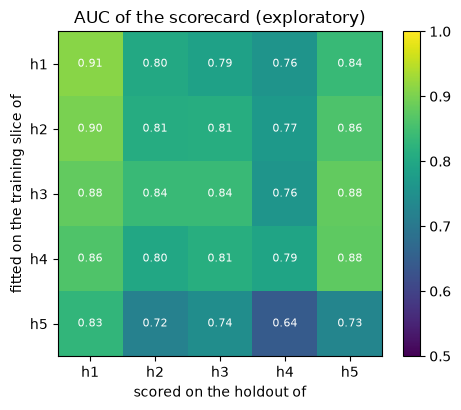

In [9]:
# Build the transfer matrix of the scorecard, check its diagonal against step 2 and draw it
matrix = np.zeros((5, 5))
for fitted, h in enumerate(horizons):
    for cell in docs[h]["outputs"]["transfer"]["cells"]:
        if cell["rung"] == "P1":
            matrix[fitted, cell["scored_on_years"] - 1] = cell["auc"]
diagonal = np.array([auc[h]["P1-scorecard"]["auc"] for h in horizons])
print("diagonal equals the holdout AUC of step 2:", bool(np.allclose(np.diag(matrix), diagonal)))
print({"exploratory": "exploratory"}[docs["h1"]["outputs"]["transfer"]["label"]], "|", docs["h1"]["outputs"]["transfer"]["reason"][LANG])
print(f"{'fitted on':14s}" + "".join(f"{'scored on h' + str(j + 1):>16s}" for j in range(5)))
for i in range(5):
    print(f"{'h' + str(i + 1):14s}" + "".join(f"{matrix[i, j]:16.3f}" for j in range(5)))

fig, ax = plt.subplots(figsize=(5, 4.2))
image = ax.imshow(matrix, vmin=0.5, vmax=1.0, cmap="viridis")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
ax.set_xticks(range(5))
ax.set_xticklabels([f"h{j + 1}" for j in range(5)])
ax.set_yticks(range(5))
ax.set_yticklabels([f"h{i + 1}" for i in range(5)])
ax.set_xlabel("scored on the holdout of")
ax.set_ylabel("fitted on the training slice of")
ax.set_title("AUC of the scorecard (exploratory)")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()


### Step 7: the five files stacked

The pooled file stacks the five files with a horizon indicator, so a single model sees 43,405 company-years. It has more data and a tighter interval, and it carries the same caveat in full: whether a company repeats across the files is unknown, so a company may sit in the training slice and in the holdout under different horizons. The next cell prints the pooled counts, the committed caveat and the AUC of each model against its per-horizon average, and the single variable the P0 baseline chose on the pooled file.

In [10]:
# Print the pooled counts and caveat, and the pooled AUC against the per-horizon average
po = pooled["outputs"]
print("company-years:", po["counts"]["rows"], "| bankrupt:", po["counts"]["events"], "| rate:", round(po["counts"]["event_rate"], 4), "| holdout:", po["split"]["holdout_rows"], "/", po["split"]["holdout_events"])
print("single variable of the P0 baseline:", pooled["model"][0]["title"][LANG])
print(po["firm_overlap_caveat"][LANG])
print(f"{'model':14s} {'pooled AUC':>16s} {'mean of five horizons':>28s}")
for x in po["rungs"]:
    r = rung_of(x)
    print(f"{r:14s} {x['discrimination']['auc']:16.3f} {np.mean([auc[h][r]['auc'] for h in horizons]):28.3f}")


company-years: 43405 | bankrupt: 2091 | rate: 0.0482 | holdout: 13023 / 628
single variable of the P0 baseline: Single variable (Attr27_missing)
The five files are stacked with a horizon indicator. The UCI page gives no firm identifier and no date, so whether a company appears in several files is unknown (UNVERIFIED, 08 l.855-856). No feature vector is shared by two files, but a company's ratios change from year to year, so that is not evidence that firms do not repeat. A pooled score may therefore be flattered by repeated firms.
model                pooled AUC        mean of five horizons
P0-single                 0.652                        0.702
P1-scorecard              0.865                        0.816
P2a-l1                    0.882                        0.837
P2b-pltr                  0.917                        0.906
P3-ebm                    0.945                        0.921
P4-lightgbm               0.970                        0.931
P4-xgboost                0.964      

## Results

- **No term structure.** The five event rates fall with the horizon (6.9%, 5.3%, 4.7%, 3.9%, 3.9%) where a cumulative PD would rise: the files are different samples, so the expected credit loss under the five horizons is not computed (the committed effect is null, with the reason). A lifetime estimate needs a cohort followed through time, which this data cannot give.
- **Ranking is strong and uneven.** With 64 financial ratios the scorecard reaches an AUC of 0.91 at h1 and 0.73 at h5; the boosted models reach 0.94 to 0.95 at h1 and 0.93 to 0.94 at h5. The intervals are wide (the scorecard's at h5 runs from 0.67 to 0.78, with 81 bankruptcies in the holdout).
- **The scorecard overfits at the longest horizon.** Its train-holdout gap is 0.005 at h1, 0.065 at h4 and 0.092 at h5, above the 0.05 tolerance in the last two, and the same flag rises for the other models at several horizons: with few bankruptcies a flexible model learns the training slice. The recomputed flags equal the committed ones.
- **Challengers rank better, not always significantly.** At h1 the penalised regression ties the scorecard (DeLong p 0.90), while the trees, the explainable boosting machine and the two boosted models gain 0.02 to 0.04 AUC points (p below 0.003); at h5 all five are significant. The recomputed DeLong p-values equal the committed ones to the precision of the committed intervals. The grade disagreement (up to about 50% of the companies) is the practical cost of changing the model.
- **The calibration is mixed.** The level test (Jeffreys) is green for the scorecard at every horizon, and the Hosmer-Lemeshow p-values recompute exactly from their statistics; some models are red on the fit test at some horizon (the one-variable baseline at every horizon), as notebook 03 explained for the level and the fit.
- **The transfer matrix cannot be read as robustness.** Several off-diagonal cells are above the diagonal: the scorecard fitted on h4 scores 0.875 on the h5 holdout, above the 0.728 of the scorecard fitted on h5 itself. With unknown company overlap, a high transfer AUC is as likely to come from repeated companies as from a model that generalises. The pooled model reaches 0.97 with LightGBM, the same limit amplified by the larger sample, and the pooled one-variable baseline chose the indicator that ratio Attr27 is missing, not a ratio itself (AUC 0.652).

What this notebook does not show: the fit of the models themselves (the pipeline's `data-pipeline/pipeline/cases/c02/`), a rating of corporate risk in any other country, or an out-of-time test: the files have no date, and the case states that no out-of-time claim is made (`out_of_time_claim` false).

## Summary

- Five files of different forecast years are five samples, not one cohort: their event rates need not grow with the horizon, and no term structure or lifetime loss is read from them.
- The ladder is compared on each horizon with the AUC and its DeLong interval; the overfit gap flags the longest horizon, where few bankruptcies meet 64 ratios.
- A committed p-value can be recomputed from the numbers beside it: the DeLong p from the interval, the Hosmer-Lemeshow p from its statistic, the Jeffreys test from the size, defaults and mean PD.
- A cross-file transfer and a pooled model are exploratory: without a company identifier they cannot be called out-of-sample.

**What to try next.** Pick the horizon with the weakest scorecard (h5) and read its reliability bins in `h5.json` against the model with the best calibration; then continue with notebook 06, which places the challengers of C01 in the state of the art.

## References

- Tomczak, S. (2016), Polish Companies Bankruptcy, UCI Machine Learning Repository (CC BY 4.0), https://doi.org/10.24432/C5F600 (the attribution recorded in `data/derived/C02/raw-sources.txt`). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf